# Iterative Solvers

**Source:** https://labs.acme.byu.edu/Volume1/IterativeSolvers/IterativeSolvers.html

For large sparse systems $A\mathbf{x}=\mathbf{b}$, direct factorization is often too expensive. Iterative methods build a sequence $\mathbf{x}^{(k)}$ that converges to the solution, and each step costs about one sparse matrix-vector product. This lab implements Jacobi, Gauss-Seidel, and Successive Over-Relaxation (SOR), then uses SOR to solve a finite-difference model of steady-state heat flow on a plate.

Every method stops when $\|\mathbf{x}^{(k-1)} - \mathbf{x}^{(k)}\|_\infty < \varepsilon$ or after $N$ iterations.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg as la
from scipy import sparse
from scipy.sparse import linalg as spla

rng = np.random.default_rng(0)

The lab's generator for strictly diagonally dominant test matrices. It takes an optional seed here so the notebook is reproducible.

In [2]:
def diag_dom(n, num_entries=None, as_sparse=False, seed=None):
    """Generate a strictly diagonally dominant (n, n) matrix.
    Parameters:
        n (int): The dimension of the system.
        num_entries (int): The number of nonzero values.
            Defaults to n^(3/2)-n.
        as_sparse: If True, an equivalent sparse CSR matrix is returned.
    Returns:
        A ((n, n) ndarray): A (n, n) strictly diagonally dominant matrix.
    """
    rng = np.random.default_rng(seed)

    if num_entries is None:
        num_entries = int(n**1.5) - n

    A = sparse.lil_matrix((n, n))
    rows = rng.choice(n, size=num_entries)
    cols = rng.choice(n, size=num_entries)
    data = rng.integers(-4, 4, size=num_entries)

    for i in range(num_entries):
        A[rows[i], cols[i]] = data[i]

    B = A.tocsr()               # Convert to row format for the next step

    for i in range(n):
        A[i, i] = abs(B[i]).sum() + 1

    return A.tocsr() if as_sparse else A.toarray()

## The Jacobi Method

Split $A = D + L + U$ into diagonal, strictly lower, and strictly upper parts. Solving each equation for its diagonal variable gives

$$\mathbf{x}^{(k+1)} = \mathbf{x}^{(k)} + D^{-1}(\mathbf{b} - A\mathbf{x}^{(k)}).$$

$D^{-1}$ is never formed. With $\mathbf{d}$ the diagonal of $A$, multiplying by $D^{-1}$ is just elementwise division by $\mathbf{d}$.

The lab's $3\times3$ example:

$$\begin{aligned} 2x_1 - x_3 &= 3\\ -x_1 + 3x_2 + 2x_3 &= 3\\ x_2 + 3x_3 &= -1\end{aligned}$$

with solution $(1, 2, -1)$.

In [3]:
A_ex = np.array([[2., 0, -1], [-1, 3, 2], [0, 1, 3]])
b_ex = np.array([3., 3, -1])

---

## Problems 1-2: Jacobi with Convergence Plot

The function returns the solution and also records the absolute error $\|A\mathbf{x}^{(k)} - \mathbf{b}\|_\infty$ at each step. With `plot=True` it draws that error on a log scale. The iteration count is returned too (as `info`), so the examples can report it.

In [4]:
def jacobi(A, b, tol=1e-8, maxiter=100, plot=False, info=False):
    """Calculate the solution to the system Ax = b via the Jacobi Method.

    Parameters:
        A ((n,n) ndarray): A square matrix.
        b ((n ,) ndarray): A vector of length n.
        tol (float): The convergence tolerance.
        maxiter (int): The maximum number of iterations to perform.
        plot (bool): If True, plot the absolute error at each iteration.
        info (bool): If True, also return the number of iterations performed.

    Returns:
        ((n,) ndarray): The solution to system Ax = b.
    """
    d = np.diag(A).astype(float)
    x = np.zeros(len(b))
    errors = []
    for k in range(1, maxiter + 1):
        x_new = x + (b - A @ x) / d
        errors.append(la.norm(A @ x_new - b, ord=np.inf))
        converged = la.norm(x_new - x, ord=np.inf) < tol
        x = x_new
        if converged:
            break
    if plot:
        plt.figure(figsize=(7, 3.5))
        plt.semilogy(range(1, len(errors) + 1), errors)
        plt.xlabel("Iteration"); plt.ylabel(r"Absolute error $\|Ax^{(k)} - b\|_\infty$")
        plt.title("Convergence of Jacobi Method")
        plt.grid(alpha=0.3, which="both"); plt.show()
    return (x, k) if info else x


x, its = jacobi(A_ex, b_ex, info=True)
print(f"Jacobi on the lab example: x = {np.round(x, 8)} after {its} iterations")

# Reproduce the first rows of the lab's iteration table
x = np.zeros(3)
for k in range(1, 5):
    x = x + (b_ex - A_ex @ x) / np.diag(A_ex)
    print(f"x^({k}) = {x}")

Jacobi on the lab example: x = [ 1.  2. -1.] after 31 iterations
x^(1) = [ 1.5         1.         -0.33333333]
x^(2) = [ 1.33333333  1.72222222 -0.66666667]
x^(3) = [ 1.16666667  1.88888889 -0.90740741]
x^(4) = [ 1.0462963   1.99382716 -0.96296296]


Test on random diagonally dominant systems of several sizes (Problem 1), then plot the error for one of them (Problem 2).

In [5]:
for n in [5, 50, 500]:
    A = diag_dom(n, seed=n)
    b = rng.random(n)
    x, its = jacobi(A, b, info=True)
    print(f"n = {n:4d}: {its:3d} iterations, allclose(Ax, b) = {np.allclose(A @ x, b)!s:5}, "
          f"||Ax - b||_inf = {la.norm(A @ x - b, np.inf):.1e}, "
          f"||x - solve(A, b)||_inf = {la.norm(x - la.solve(A, b), np.inf):.1e}")

n =    5:  50 iterations, allclose(Ax, b) = True , ||Ax - b||_inf = 2.7e-08, ||x - solve(A, b)||_inf = 2.0e-08
n =   50:  24 iterations, allclose(Ax, b) = True , ||Ax - b||_inf = 4.1e-08, ||x - solve(A, b)||_inf = 2.8e-09
n =  500:  13 iterations, allclose(Ax, b) = False, ||Ax - b||_inf = 7.9e-08, ||x - solve(A, b)||_inf = 1.8e-09


The `allclose(Ax, b)` check from the lab can print `False` even when the solve is accurate. The stopping rule bounds the *step* size, and the solution error ends up around $10^{-9}$. The residual is that error multiplied by $A$, whose diagonal entries reach several dozen for $n=500$. `np.allclose` then compares each residual entry against `1e-8 + 1e-5 * |b_i|`, and some entries of a random $\mathbf{b}$ are close to 0. The error against a direct solve is the better measure here.

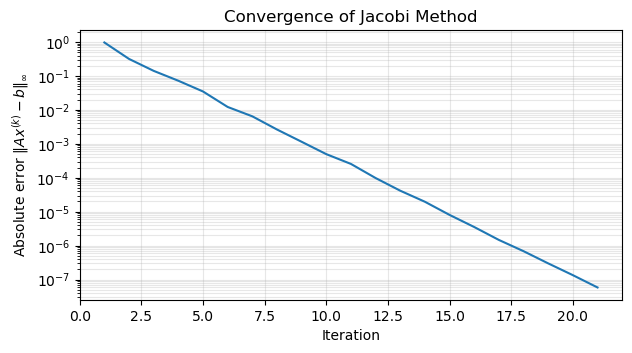

In [6]:
A = diag_dom(100, seed=1)
b = rng.random(100)
x = jacobi(A, b, plot=True)

A random dense matrix is not diagonally dominant, and Jacobi diverges on it. The iterates blow up, which is the failure mode the lab warns about.

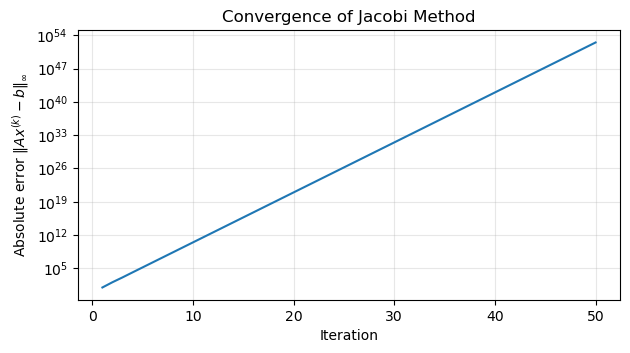

after 50 iterations, max |x_i| = 1.249e+52
spectral radius of the Jacobi iteration matrix: 11.244


In [7]:
A_bad = rng.random((10, 10))
x, its = jacobi(A_bad, rng.random(10), maxiter=50, plot=True, info=True)
print(f"after {its} iterations, max |x_i| = {np.abs(x).max():.3e}")
D_inv_LU = -(A_bad - np.diag(np.diag(A_bad))) / np.diag(A_bad)[:, None]
print("spectral radius of the Jacobi iteration matrix:", np.max(np.abs(la.eigvals(D_inv_LU))).round(3))

Jacobi converges for every starting guess exactly when the spectral radius of its iteration matrix $D^{-1}(L+U)$ is less than 1. Here it is much larger than 1.

## The Gauss-Seidel Method

Gauss-Seidel uses each new component as soon as it is computed:

$$x_i^{(k+1)} = x_i^{(k)} + \frac{1}{a_{ii}}\left(b_i - \mathbf{a}_i^T\mathbf{x}^{(k)}_i\right),$$

where $\mathbf{x}^{(k)}_i$ is the vector being updated in place, already holding the new values for components $1,\dots,i-1$. It converges for strictly diagonally dominant or symmetric positive definite $A$.

---

## Problem 3: Gauss-Seidel (dense)

In [8]:
def gauss_seidel(A, b, tol=1e-8, maxiter=100, plot=False, info=False):
    """Calculate the solution to the system Ax = b via the Gauss-Seidel Method.

    Parameters:
        A ((n, n) ndarray): A square matrix.
        b ((n, ) ndarray): A vector of length n.
        tol (float): The convergence tolerance.
        maxiter (int): The maximum number of iterations to perform.
        plot (bool): If true, plot the convergence rate of the algorithm.
        info (bool): If True, also return the number of iterations performed.

    Returns:
        x ((n,) ndarray): The solution to system Ax = b.
    """
    n = len(b)
    x = np.zeros(n)
    errors = []
    for k in range(1, maxiter + 1):
        x_old = np.copy(x)
        for i in range(n):
            x[i] += (b[i] - A[i] @ x) / A[i, i]
        errors.append(la.norm(A @ x - b, ord=np.inf))
        if la.norm(x_old - x, ord=np.inf) < tol:
            break
    if plot:
        plt.figure(figsize=(7, 3.5))
        plt.semilogy(range(1, len(errors) + 1), errors)
        plt.xlabel("Iteration"); plt.ylabel(r"Absolute error $\|Ax^{(k)} - b\|_\infty$")
        plt.title("Convergence of Gauss-Seidel Method")
        plt.grid(alpha=0.3, which="both"); plt.show()
    return (x, k) if info else x


x, its = gauss_seidel(A_ex, b_ex, info=True)
print(f"Gauss-Seidel on the lab example: x = {np.round(x, 8)} after {its} iterations")

x = np.zeros(3)
for k in range(1, 5):
    for i in range(3):
        x[i] += (b_ex[i] - A_ex[i] @ x) / A_ex[i, i]
    print(f"x^({k}) = {x}")

Gauss-Seidel on the lab example: x = [ 1.  2. -1.] after 12 iterations
x^(1) = [ 1.5         1.5        -0.83333333]
x^(2) = [ 1.08333333  1.91666667 -0.97222222]
x^(3) = [ 1.01388889  1.98611111 -0.99537037]
x^(4) = [ 1.00231481  1.99768519 -0.9992284 ]


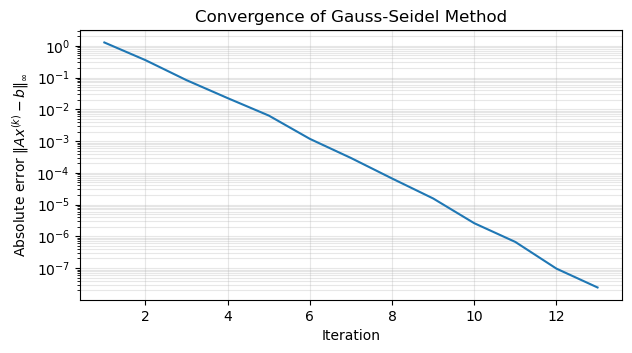

allclose(Ax, b): True


In [9]:
A = diag_dom(100, seed=1)
b = rng.random(100)
x = gauss_seidel(A, b, plot=True)
print("allclose(Ax, b):", np.allclose(A @ x, b))

Side by side on the same system, Gauss-Seidel takes about half as many iterations as Jacobi:

In [10]:
for n in [10, 100, 300]:
    A = diag_dom(n, seed=7 * n)
    b = rng.random(n)
    _, kj = jacobi(A, b, info=True)
    _, kg = gauss_seidel(A, b, info=True)
    print(f"n = {n:3d}: Jacobi {kj:3d} iterations, Gauss-Seidel {kg:3d} iterations")

n =  10: Jacobi  30 iterations, Gauss-Seidel  19 iterations
n = 100: Jacobi  19 iterations, Gauss-Seidel  13 iterations
n = 300: Jacobi  15 iterations, Gauss-Seidel  11 iterations


---

## Problem 4: Gauss-Seidel for Sparse Matrices

In CSR format, row $i$'s nonzeros are `A.data[A.indptr[i]:A.indptr[i+1]]`, in the columns listed in `A.indices`. That gives $\mathbf{a}_i^T\mathbf{x}$ without forming the row. The diagonal comes from `A.diagonal()`.

In [11]:
def gauss_seidel_sparse(A, b, tol=1e-8, maxiter=100, info=False):
    """Calculate the solution to the sparse system Ax = b via the Gauss-Seidel
    Method.

    Parameters:
        A ((n, n) csr_matrix): A (n, n) sparse CSR matrix.
        b ((n, ) ndarray): A vector of length n.
        tol (float): The convergence tolerance.
        maxiter (int): the maximum number of iterations to perform.
        info (bool): If True, also return the number of iterations performed.

    Returns:
        x ((n,) ndarray): The solution to system Ax = b.
    """
    A = sparse.csr_matrix(A)
    n = len(b)
    diag = A.diagonal()
    x = np.zeros(n)
    for k in range(1, maxiter + 1):
        x_old = np.copy(x)
        for i in range(n):
            rowstart, rowend = A.indptr[i], A.indptr[i + 1]
            Aix = A.data[rowstart:rowend] @ x[A.indices[rowstart:rowend]]
            x[i] += (b[i] - Aix) / diag[i]
        if la.norm(x_old - x, ord=np.inf) < tol:
            break
    return (x, k) if info else x


A = diag_dom(1000, as_sparse=True, seed=3)
b = rng.random(1000)
t0 = time.perf_counter()
x, its = gauss_seidel_sparse(A, b, info=True)
print(f"n = 1000, nnz = {A.nnz}: {its} iterations in {time.perf_counter() - t0:.2f} s, "
      f"allclose(Ax, b) = {np.allclose(A @ x, b)}")

n = 1000, nnz = 27290: 9 iterations in 0.06 s, allclose(Ax, b) = True


### Unit tests for Problem 4

The lab asks for graded unit tests for the sparse solver in `test_iterative_solvers.py`. They are written pytest-style below and run in place.

In [12]:
def test_gauss_seidel_sparse_matches_dense():
    A = diag_dom(50, as_sparse=True, seed=11)
    b = np.random.default_rng(11).random(50)
    assert np.allclose(gauss_seidel_sparse(A, b), gauss_seidel(A.toarray(), b))

def test_gauss_seidel_sparse_solves_system():
    for n in [10, 200, 2000]:
        A = diag_dom(n, as_sparse=True, seed=n)
        b = np.random.default_rng(n).random(n)
        x = gauss_seidel_sparse(A, b)
        assert np.allclose(A @ x, b)
        assert np.allclose(x, spla.spsolve(A.tocsc(), b))

def test_gauss_seidel_sparse_lab_example():
    x = gauss_seidel_sparse(sparse.csr_matrix(A_ex), b_ex)
    assert np.allclose(x, [1, 2, -1])

def test_gauss_seidel_sparse_maxiter():
    # One sweep is not enough to converge, so exactly one iteration is reported.
    A = diag_dom(100, as_sparse=True, seed=5)
    b = np.random.default_rng(5).random(100)
    _, k = gauss_seidel_sparse(A, b, maxiter=1, info=True)
    assert k == 1

def test_gauss_seidel_sparse_accepts_other_formats():
    A = diag_dom(30, as_sparse=True, seed=2)
    b = np.random.default_rng(2).random(30)
    assert np.allclose(gauss_seidel_sparse(A.tocsc(), b), gauss_seidel_sparse(A, b))

tests = [v for k, v in dict(globals()).items() if k.startswith("test_") and callable(v)]
for t in tests:
    t()
    print("PASS", t.__name__)

PASS test_gauss_seidel_sparse_matches_dense


PASS test_gauss_seidel_sparse_solves_system
PASS test_gauss_seidel_sparse_lab_example
PASS test_gauss_seidel_sparse_maxiter
PASS test_gauss_seidel_sparse_accepts_other_formats


## Successive Over-Relaxation

SOR scales each Gauss-Seidel correction by a relaxation factor $\omega$:

$$x_i^{(k+1)} = x_i^{(k)} + \frac{\omega}{a_{ii}}\left(b_i - \mathbf{a}_i^T\mathbf{x}^{(k)}_i\right).$$

$\omega = 1$ is Gauss-Seidel. For symmetric positive definite systems, SOR converges for any $0 < \omega < 2$, and a well-chosen $\omega > 1$ can cut the iteration count dramatically.

---

## Problem 5: SOR

In [13]:
def sor(A, b, omega, tol=1e-8, maxiter=100):
    """Calculate the solution to the system Ax = b via Successive Over-
    Relaxation.

    Parameters:
        A ((n, n) csr_matrix): A (n, n) sparse matrix.
        b ((n, ) Numpy Array): A vector of length n.
        omega (float in (0,2)): The relaxation factor.
        tol (float): The convergence tolerance.
        maxiter (int): The maximum number of iterations to perform.

    Returns:
        ((n,) ndarray): The solution to system Ax = b.
        (bool): Whether or not SOR converged.
        (int): The number of iterations computed.
    """
    A = sparse.csr_matrix(A)
    n = len(b)
    diag = A.diagonal()
    x = np.zeros(n)
    for k in range(1, maxiter + 1):
        x_old = np.copy(x)
        for i in range(n):
            rowstart, rowend = A.indptr[i], A.indptr[i + 1]
            Aix = A.data[rowstart:rowend] @ x[A.indices[rowstart:rowend]]
            x[i] += omega * (b[i] - Aix) / diag[i]
        if la.norm(x_old - x, ord=np.inf) < tol:
            return x, True, k
    return x, False, maxiter


A = diag_dom(500, as_sparse=True, seed=9)
b = rng.random(500)
for omega in [0.8, 1.0, 1.1, 1.3]:
    x, conv, its = sor(A, b, omega)
    print(f"omega = {omega}: converged = {conv}, iterations = {its:3d}, "
          f"||x - spsolve(A, b)||_inf = {la.norm(x - spla.spsolve(A.tocsc(), b), np.inf):.1e}")

omega = 0.8: converged = True, iterations =  16, ||x - spsolve(A, b)||_inf = 3.4e-09
omega = 1.0: converged = True, iterations =  10, ||x - spsolve(A, b)||_inf = 2.1e-10
omega = 1.1: converged = True, iterations =  13, ||x - spsolve(A, b)||_inf = 9.0e-10


omega = 1.3: converged = True, iterations =  26, ||x - spsolve(A, b)||_inf = 2.5e-09


On this strictly diagonally dominant system, Gauss-Seidel already converges quickly, and over-relaxing doesn't help. SOR pays off on systems like the next one, where Gauss-Seidel is slow.

## A Finite Difference Method: Heat on a Plate

Laplace's equation $u_{xx} + u_{yy} = 0$ models the steady-state temperature of a square plate. Here the left and right edges are held at $100^\circ$C and the top and bottom at $0^\circ$C. On a grid of $n\times n$ interior points, the centered-difference stencil gives

$$-4U_{i,j} + U_{i+1,j} + U_{i-1,j} + U_{i,j+1} + U_{i,j-1} = 0.$$

Known boundary values move to the right side. Ordering the unknowns row by row gives $A\mathbf{u} = \mathbf{b}$ with block-tridiagonal $A$: blocks $B = \mathrm{tridiag}(1, -4, 1)$ on the diagonal and $I$ off it. $\mathbf{b}$ is $-100$ wherever an interior point touches the left or right edge.

---

## Problem 6: Solve the Hot Plate with SOR

In [14]:
def laplace_system(n):
    """Return the (n^2, n^2) CSR matrix A and the vector b for the hot plate."""
    B = sparse.diags([1., -4., 1.], [-1, 0, 1], shape=(n, n))
    I_off = sparse.diags([1., 1.], [-1, 1], shape=(n, n))
    A = sparse.kron(sparse.identity(n), B) + sparse.kron(I_off, sparse.identity(n))
    row = np.zeros(n)
    row[0] = row[-1] = -100
    b = np.tile(row, n).astype(float)
    return A.tocsr(), b


def hot_plate(n, omega, tol=1e-8, maxiter=100, plot=False):
    """Generate the system Au = b and then solve it using sor().
    If plot is True, visualize the solution with a heatmap.

    Parameters:
        n (int): Determines the size of A and b.
            A is (n^2, n^2) and b is one-dimensional with n^2 entries.
        omega (float in (0,2)): The relaxation factor.
        tol (float): The iteration tolerance.
        maxiter (int): The maximum number of iterations.
        plot (bool): Whether or not to visualize the solution.

    Returns:
        ((n^2,) ndarray): The 1-D solution vector u of the system Au = b.
        (bool): Whether or not SOR converged.
        (int): The number of computed iterations in SOR.
    """
    A, b = laplace_system(n)
    u, conv, its = sor(A, b, omega, tol=tol, maxiter=maxiter)
    if plot:
        plt.figure(figsize=(5.5, 4.5))
        plt.pcolormesh(u.reshape((n, n)), cmap="coolwarm")
        plt.colorbar(label="temperature (°C)")
        plt.gca().set_aspect("equal")
        plt.title(f"Hot plate, n = {n}, $\\omega$ = {omega}\n"
                  f"converged = {conv} after {its} iterations")
        plt.show()
    return u, conv, its

First, check the matrix against the $16\times16$ example in the lab ($n = 4$):

In [15]:
A4, b4 = laplace_system(4)
print(A4.toarray().astype(int))
print("b =", b4)

[[-4  1  0  0  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 1 -4  1  0  0  1  0  0  0  0  0  0  0  0  0  0]
 [ 0  1 -4  1  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  1 -4  0  0  0  1  0  0  0  0  0  0  0  0]
 [ 1  0  0  0 -4  1  0  0  1  0  0  0  0  0  0  0]
 [ 0  1  0  0  1 -4  1  0  0  1  0  0  0  0  0  0]
 [ 0  0  1  0  0  1 -4  1  0  0  1  0  0  0  0  0]
 [ 0  0  0  1  0  0  1 -4  0  0  0  1  0  0  0  0]
 [ 0  0  0  0  1  0  0  0 -4  1  0  0  1  0  0  0]
 [ 0  0  0  0  0  1  0  0  1 -4  1  0  0  1  0  0]
 [ 0  0  0  0  0  0  1  0  0  1 -4  1  0  0  1  0]
 [ 0  0  0  0  0  0  0  1  0  0  1 -4  0  0  0  1]
 [ 0  0  0  0  0  0  0  0  1  0  0  0 -4  1  0  0]
 [ 0  0  0  0  0  0  0  0  0  1  0  0  1 -4  1  0]
 [ 0  0  0  0  0  0  0  0  0  0  1  0  0  1 -4  1]
 [ 0  0  0  0  0  0  0  0  0  0  0  1  0  0  1 -4]]
b = [-100.    0.    0. -100. -100.    0.    0. -100. -100.    0.    0. -100.
 -100.    0.    0. -100.]


The lab's defaults (`tol=1e-8`, `maxiter=100`) are far from enough for this system, so the run below raises both. The result is checked against a direct sparse solve.

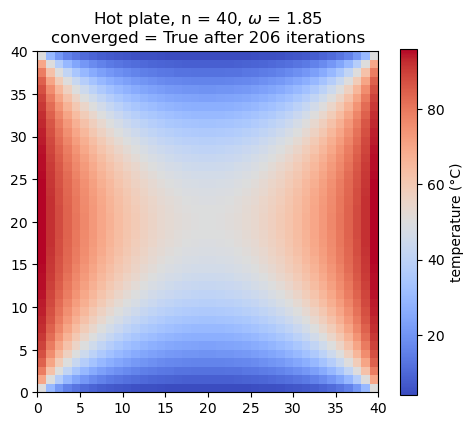

max |u - spsolve| = 8.571471710183687e-08


In [16]:
n = 40
u, conv, its = hot_plate(n, 1.85, tol=1e-8, maxiter=2000, plot=True)
A, b = laplace_system(n)
print("max |u - spsolve| =", np.abs(u - spla.spsolve(A.tocsc(), b)).max())

In [17]:
u, conv, its = hot_plate(40, 1.0, plot=False)
print(f"Gauss-Seidel with the default maxiter=100: converged = {conv}, iterations = {its}")

Gauss-Seidel with the default maxiter=100: converged = False, iterations = 100


---

## Problem 7: Choosing $\omega$

Run SOR on the $n=20$ plate (tol $=10^{-2}$, maxiter $=1000$) for $\omega = 1, 1.05, \dots, 1.95$, and plot the iteration count against $\omega$.

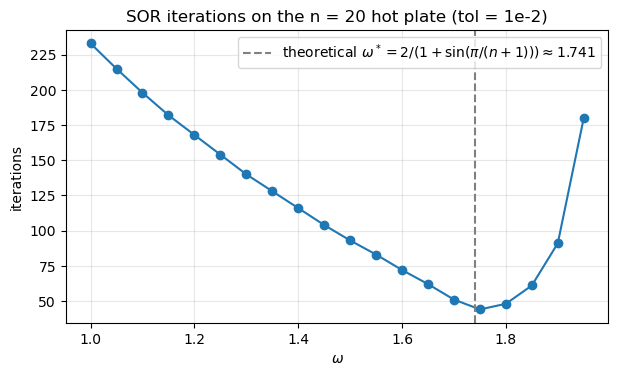

omega = 1.00:  233
omega = 1.05:  215
omega = 1.10:  198
omega = 1.15:  182
omega = 1.20:  168
omega = 1.25:  154
omega = 1.30:  140
omega = 1.35:  128
omega = 1.40:  116
omega = 1.45:  104
omega = 1.50:   93
omega = 1.55:   83
omega = 1.60:   72
omega = 1.65:   62
omega = 1.70:   51
omega = 1.75:   44
omega = 1.80:   48
omega = 1.85:   61
omega = 1.90:   91
omega = 1.95:  180
Best omega: 1.75


In [18]:
def prob7():
    """Run hot_plate() with omega = 1, 1.05, 1.1, ..., 1.9, 1.95, tol=1e-2,
    and maxiter = 1000 with A and b generated with n=20. Plot the iterations
    computed as a function of omega.
    """
    omegas = np.arange(1, 2, 0.05)
    iters = np.array([hot_plate(20, w, tol=1e-2, maxiter=1000)[2] for w in omegas])
    best = omegas[np.argmin(iters)]

    n = 20
    w_theory = 2 / (1 + np.sin(np.pi / (n + 1)))
    plt.figure(figsize=(7, 3.8))
    plt.plot(omegas, iters, "o-")
    plt.axvline(w_theory, color="gray", ls="--",
                label=fr"theoretical $\omega^* = 2/(1+\sin(\pi/(n+1))) \approx {w_theory:.3f}$")
    plt.xlabel(r"$\omega$"); plt.ylabel("iterations")
    plt.title("SOR iterations on the n = 20 hot plate (tol = 1e-2)")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
    for w, k in zip(omegas, iters):
        print(f"omega = {w:.2f}: {k:4d}")
    return best

best = prob7()
print("Best omega:", round(best, 2))

## Discussion

- On the lab's $3\times3$ example, Gauss-Seidel stops after 12 iterations, matching the lab's table. Jacobi stops after 31: its iterates agree with the solution to 8 decimal places at $\mathbf{x}^{(29)}$, as the lab's table shows, but the step-size test needs two more iterations to trigger. On the random diagonally dominant systems, Gauss-Seidel took 25-40% fewer iterations than Jacobi.
- The hot-plate matrix is not strictly diagonally dominant, but $-A$ is symmetric positive definite, so Gauss-Seidel and SOR still converge. Gauss-Seidel converges slowly: its spectral radius is close to 1 and gets closer as $n$ grows.
- For this model problem, the optimal relaxation factor is known in closed form, $\omega^* = 2/(1+\sin(\pi/(n+1)))$, about $1.74$ for $n=20$. The empirical minimum in Problem 7 lands close to it, and the plot shows the sharp rise in iterations as $\omega$ moves past the optimum toward 2.